# Análise de Pareto — Global e por Paradigma

Lê os `Modelos<Paradigma>_CV_Consolidado.xlsx` (curvas completas de Backward Elimination, uma aba por ranking) e, para cada curva, marca o ponto de "joelho" (Kneedle, geométrico) e o ponto da regra 1-SE (Estatístico). Gera **dois tipos de gráfico**: um **global**, com todos os paradigmas juntos, e um **por paradigma** (DT, RF, GB, SVM, MLP, GNB e LogReg_Lasso separadamente) -- porque num gráfico só, o paradigma mais forte tende a dominar a fronteira de Pareto e esconder os demais.

Os arquivos `Resumo_Geral_Modelos<Paradigma>_CV.xlsx` (1 linha por ranking, não uma curva) são excluídos da leitura, porque o padrão `*Modelos*.xlsx` também os casaria e o Kneedle/Estatístico rodaria sobre uma curva de um ponto só.

A seção 8 compara Proposed e Literature (Sensibilidade, Especificidade, AUC e Acurácia Balanceada) com o teste de Mann-Whitney, por paradigma e por estratégia (Kneedle e Estatístico).

**Leitura**: o caderno lê os arquivos consolidados do caderno 4 (`Modelos<Paradigma>_CV_Consolidado.xlsx`, 1 por paradigma, 1 aba por ranking) com `pd.read_excel(..., sheet_name=None)` e trata cada aba como uma curva (seção 4).

### 1. Configurações

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import glob
import os
import re
from datetime import datetime
from matplotlib.lines import Line2D

FOLDER_PATH = os.getcwd()
# Procura os arquivos consolidados (1 por paradigma), não mais 1 arquivo por ranking
FILE_PATTERN = "Modelos*_CV_Consolidado.xlsx"

# Arquivos-alvo definidos por sufixo (métricas CEQ do Bloco 1, independente do paradigma).
# Sem ".xlsx" no final -- agora comparamos contra o NOME DA ABA (que é o nome do ranking, ex. "Ranking_Cp_Original"), não contra um nome de arquivo
TARGET_SUFFIXES = [
    "_u_Original", "_u_Normalizado",
    "_Ppk_Original", "_Ppk_Normalizado",
    "_Pp_Original", "_Pp_Normalizado",
    "_p_Original", "_p_Normalizado",
    "_np_Original", "_np_Normalizado",
    "_Cpk_Original", "_Cpk_Normalizado",
    "_Cp_Original", "_Cp_Normalizado",
    "_c_Original", "_c_Normalizado",
]


def is_target_file(nome_ranking, suffixes=TARGET_SUFFIXES):
    '''nome_ranking é o nome da aba/ranking (ex.: Ranking_Cp_Original), não mais um
    nome de arquivo -- antes da consolidação, cada ranking era o próprio arquivo
    .xlsx e esta função comparava o nome do arquivo; agora compara o nome da aba.'''
    return any(nome_ranking.endswith(suf) for suf in suffixes)


def extrair_paradigma(filename):
    '''Extrai o prefixo do paradigma a partir de 'Modelos<Paradigma>_CV_Consolidado.xlsx'
    (ex.: DT, RF, GB, SVM, MLP, GNB, LogReg_Lasso). Não-guloso até o primeiro '_CV_'
    -- antes usava [A-Za-z]+, que quebrava em paradigmas com underscore no nome
    (LogReg_Lasso virava "Desconhecido"). Funciona igual com o nome do arquivo
    consolidado (o '_CV_' continua lá, só o que vem depois mudou de '<Ranking>.xlsx'
    para 'Consolidado.xlsx').'''
    m = re.match(r"^Modelos(.+?)_CV_", filename)
    return m.group(1) if m else "Desconhecido"


### 2. Funções de cálculo (Kneedle, 1-SE, Fronteira de Pareto)

In [2]:
def get_kneedle_idx(df, col_x, col_y):
    """Algoritmo 1: Kneedle (Geométrico)"""
    df_sorted = df.sort_values(by=col_x, ascending=True).copy()
    x = df_sorted[col_x].values
    y = df_sorted[col_y].values

    if (x.max() - x.min()) == 0 or (y.max() - y.min()) == 0:
        return df_sorted.index[0]

    x_norm = (x - x.min()) / (x.max() - x.min())
    y_norm = (y - y.min()) / (y.max() - y.min())

    coords = np.vstack((x_norm, y_norm)).T
    vec_line = coords[-1] - coords[0]
    vec_points = coords - coords[0]

    norm = np.linalg.norm(vec_line)
    if norm == 0:
        return df_sorted.index[0]

    # Distância perpendicular via produto vetorial 2D (escalar: ax*by - ay*bx) --
    # calculado manualmente em vez de np.cross, que a partir do NumPy 2.4 passou a
    # EXIGIR vetores 3D e quebra com a entrada 2D clássica usada aqui.
    distances = (vec_line[0] * vec_points[:, 1] - vec_line[1] * vec_points[:, 0]) / norm
    knee_idx_sorted = np.argmax(np.abs(distances))
    return df_sorted.iloc[knee_idx_sorted].name


def get_statistical_idx(df, col_target, col_std):
    """Algoritmo 2: Estatístico (1-SE Rule)"""
    df_sorted = df.sort_values(by="Nº de Atributos", ascending=True)
    best_idx = df_sorted[col_target].idxmax()
    std_val = df_sorted.loc[best_idx, col_std] if col_std in df_sorted.columns else 0
    limit = df_sorted.loc[best_idx, col_target] - std_val
    candidates = df_sorted[df_sorted[col_target] >= limit]
    return candidates.iloc[0].name if not candidates.empty else best_idx


def get_pareto_frontier(df_subset):
    """Fronteira de Pareto para o subconjunto de curvas passado (pode ser tudo -> fronteira
    global, ou só um paradigma -> fronteira daquele paradigma)."""
    df_sorted = df_subset.sort_values(by="Nº de Atributos", ascending=True)
    pareto_points = []
    max_acc_so_far = -np.inf

    for _, row in df_sorted.iterrows():
        acc = row["Acurácia Balanceada Média"]
        if acc > max_acc_so_far:
            pareto_points.append(row)
            max_acc_so_far = acc

    return pd.DataFrame(pareto_points)


### 3. Plotagem (reutilizável para o gráfico global e para cada paradigma)

Só os pontos Kneedle/Estatístico que caem sobre a fronteira de Pareto (deste escopo -- global ou de um paradigma) ganham rótulo de texto no gráfico, em fonte maior e negrito, para destacar os "vencedores" sem poluir o gráfico com todos os métodos.

In [3]:
def plot_analysis_colored(all_points_df, highlights_df, titulo, nome_arquivo_base):
    sns.set_theme(style="whitegrid")
    fig, ax = plt.subplots(figsize=(18, 11))

    # 1. Nuvem de fundo (cinza)
    sns.scatterplot(
        data=all_points_df,
        x="Nº de Atributos",
        y="Acurácia Balanceada Média",
        color="lightgray",
        alpha=0.25,
        s=30,
        ax=ax,
        label="_nolegend_"
    )

    # 2. Fronteira de Pareto (deste escopo)
    pareto = get_pareto_frontier(all_points_df)
    ax.plot(
        pareto["Nº de Atributos"],
        pareto["Acurácia Balanceada Média"],
        color="red",
        linestyle="--",
        linewidth=2.2,
        label="Fronteira de Pareto",
        zorder=5
    )

    pareto_tuples = list(zip(
        pareto["Nº de Atributos"].values,
        pareto["Acurácia Balanceada Média"].values
    ))

    unique_rankings = highlights_df["Ranking"].unique()

    for ranking in unique_rankings:
        subset = highlights_df[highlights_df["Ranking"] == ranking]

        is_target = is_target_file(ranking)
        color = "tab:blue" if is_target else "tab:green"

        marker_kneedle = "o"
        marker_stat = "s"

        k_s = 220 if is_target else 120
        s_s = 140 if is_target else 90
        z_k = 12 if is_target else 10
        z_s = 11 if is_target else 9

        clean_name = ranking.replace(".xlsx", "").replace("Modelos", "").replace("_", " ").strip()
        label_for_legend = f"[COMPARAÇÃO] {clean_name}" if is_target else clean_name

        # Kneedle
        kneedle_pt = subset[subset["Tipo"] == "Kneedle"]
        if not kneedle_pt.empty:
            ax.scatter(
                kneedle_pt["Nº de Atributos"],
                kneedle_pt["Acurácia Balanceada Média"],
                marker=marker_kneedle,
                s=k_s,
                color=color,
                edgecolors="black",
                linewidths=0.9,
                zorder=z_k
            )
            for _, row in kneedle_pt.iterrows():
                if any(
                    np.isclose(row["Nº de Atributos"], px, atol=1e-6, rtol=1e-6) and
                    np.isclose(row["Acurácia Balanceada Média"], py, atol=1e-6, rtol=1e-6)
                    for px, py in pareto_tuples
                ):
                    ax.annotate(
                        label_for_legend,
                        xy=(row["Nº de Atributos"], row["Acurácia Balanceada Média"]),
                        xytext=(6, 6),
                        textcoords="offset points",
                        fontsize=13,
                        fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.9),
                        zorder=30,
                        ha="left",
                        va="bottom"
                    )

        # Estatístico
        stat_pt = subset[subset["Tipo"] == "Estatístico"]
        if not stat_pt.empty:
            ax.scatter(
                stat_pt["Nº de Atributos"],
                stat_pt["Acurácia Balanceada Média"],
                marker=marker_stat,
                s=s_s,
                color=color,
                edgecolors="black",
                linewidths=0.9,
                zorder=z_s
            )
            for _, row in stat_pt.iterrows():
                if any(
                    np.isclose(row["Nº de Atributos"], px, atol=1e-6, rtol=1e-6) and
                    np.isclose(row["Acurácia Balanceada Média"], py, atol=1e-6, rtol=1e-6)
                    for px, py in pareto_tuples
                ):
                    ax.annotate(
                        label_for_legend,
                        xy=(row["Nº de Atributos"], row["Acurácia Balanceada Média"]),
                        xytext=(6, -8),
                        textcoords="offset points",
                        fontsize=13,
                        fontweight="bold",
                        bbox=dict(boxstyle="round,pad=0.3", fc="white", ec="none", alpha=0.9),
                        zorder=30,
                        ha="left",
                        va="top"
                    )

    legend_elements_shapes = [
        Line2D([0], [0], marker="o", color="w", markerfacecolor="gray", markersize=12,
               markeredgecolor="black", label="Kneedle (bolinha)"),
        Line2D([0], [0], marker="s", color="w", markerfacecolor="gray", markersize=10,
               markeredgecolor="black", label="Estatístico (quadrado)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:blue", markersize=10,
               markeredgecolor="black", label="Grupo Comparação (azul)"),
        Line2D([0], [0], marker="o", color="w", markerfacecolor="tab:green", markersize=10,
               markeredgecolor="black", label="Outros Arquivos (verde)"),
        Line2D([0], [0], color="red", linestyle="--", lw=2, label="Fronteira de Pareto")
    ]

    ax.legend(
        handles=legend_elements_shapes,
        title="Legenda",
        loc="upper left",
        bbox_to_anchor=(1.02, 1.0),
        frameon=True,
        fontsize=10,
        title_fontsize=11
    )

    plt.title(titulo, fontsize=18)
    plt.xlabel("Complexidade (Nº de Atributos)", fontsize=14)
    plt.ylabel("Acurácia Balanceada Média", fontsize=14)
    plt.subplots_adjust(right=0.72)

    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    filename = f"{nome_arquivo_base}_{timestamp}.png"
    plt.savefig(filename, dpi=300, bbox_inches="tight")
    plt.show()
    print(f"Gráfico gerado: {filename}")


### 4. Leitura dos arquivos

Cada arquivo `Modelos<Paradigma>_CV_Consolidado.xlsx` tem várias abas (1 por ranking). `pd.read_excel(caminho, sheet_name=None)` devolve um dicionário `{nome_da_aba: DataFrame}` com todas de uma vez, e cada aba é tratada como uma curva (mesma lógica de Kneedle/Estatístico). O nome do ranking vem do nome da aba.

In [4]:
# Colunas extras capturadas nos pontos Kneedle/Estatístico, além de Nº de Atributos
# e Acurácia Balanceada Média -- necessárias para a Tabela 14 (Sensitivity, Specificity, AUC-ROC)
COLUNAS_EXTRA = ["Sensibilidade Média", "Especificidade Média", "AUC Média"]

# Métricas para as quais também se guardam os 5 valores brutos por fold (colunas `_Por_Fold` do caderno 4),
# usados na comparação da seção 8.
METRICAS_SIGNIFICANCIA = ["Acurácia Balanceada", "Sensibilidade", "Especificidade", "AUC"]


def ler_curvas():
    full_path = os.path.join(FOLDER_PATH, FILE_PATTERN)
    todos_os_arquivos = glob.glob(full_path)

    # 🚫 Exclui os resumos (1 linha por ranking) -- só queremos as curvas completas
    # (o padrão já é "Modelos*_CV_Consolidado.xlsx", então Resumo_Geral_* nem aparece
    # aqui -- o filtro é mantido por segurança, caso o padrão do nome mude no futuro)
    arquivos = [f for f in todos_os_arquivos if "Resumo_Geral" not in os.path.basename(f)]
    excluidos = len(todos_os_arquivos) - len(arquivos)

    print(f"Lendo {len(arquivos)} arquivo(s) consolidado(s) (1 por paradigma) "
          f"({excluidos} arquivo(s) 'Resumo_Geral' excluído(s)).")

    all_data_list = []
    highlights_list = []

    for file_path in arquivos:
        file_name = os.path.basename(file_path)
        paradigma = extrair_paradigma(file_name)

        try:
            # Sheet_name=None lê TODAS as abas de uma vez, devolvendo {nome_da_aba: DataFrame} -- cada aba é um ranking
            todas_as_abas = pd.read_excel(file_path, sheet_name=None)
        except Exception as e:
            print(f"Erro ao abrir {file_name}: {e}")
            continue

        for nome_ranking, df in todas_as_abas.items():
            try:
                if "Nº de Atributos" not in df.columns or "Acurácia Balanceada Média" not in df.columns:
                    print(f"Aviso: aba '{nome_ranking}' de '{file_name}' não contém as colunas "
                          f"necessárias. Pulando.")
                    continue

                colunas_extra_presentes = [c for c in COLUNAS_EXTRA if c in df.columns]

                df_temp = df[["Nº de Atributos", "Acurácia Balanceada Média"]].copy()
                df_temp["Ranking"] = nome_ranking
                df_temp["Paradigma"] = paradigma
                all_data_list.append(df_temp)

                for idx, tipo in [
                    (get_kneedle_idx(df, "Nº de Atributos", "Acurácia Balanceada Média"), "Kneedle"),
                    (get_statistical_idx(df, "Acurácia Balanceada Média", "Acurácia Balanceada Desvio"), "Estatístico"),
                ]:
                    registro = {
                        "Ranking": nome_ranking, "Paradigma": paradigma, "Tipo": tipo,
                        "Nº de Atributos": df.loc[idx, "Nº de Atributos"],
                        "Acurácia Balanceada Média": df.loc[idx, "Acurácia Balanceada Média"],
                    }
                    for col in colunas_extra_presentes:
                        registro[col] = df.loc[idx, col]

                    # Guarda os 5 valores brutos por fold (colunas `_Por_Fold` do caderno 4)
                    for metrica in METRICAS_SIGNIFICANCIA:
                        col_fold = f"{metrica}_Por_Fold"
                        if col_fold in df.columns:
                            registro[col_fold] = df.loc[idx, col_fold]

                    highlights_list.append(registro)

            except Exception as e:
                print(f"Erro na aba '{nome_ranking}' de {file_name}: {e}")

    if not all_data_list or not highlights_list:
        return None, None

    return pd.concat(all_data_list, ignore_index=True), pd.DataFrame(highlights_list)


### 5. Processamento: gráfico global + um gráfico por paradigma

Lendo 7 arquivo(s) consolidado(s) (1 por paradigma) (0 arquivo(s) 'Resumo_Geral' excluído(s)).


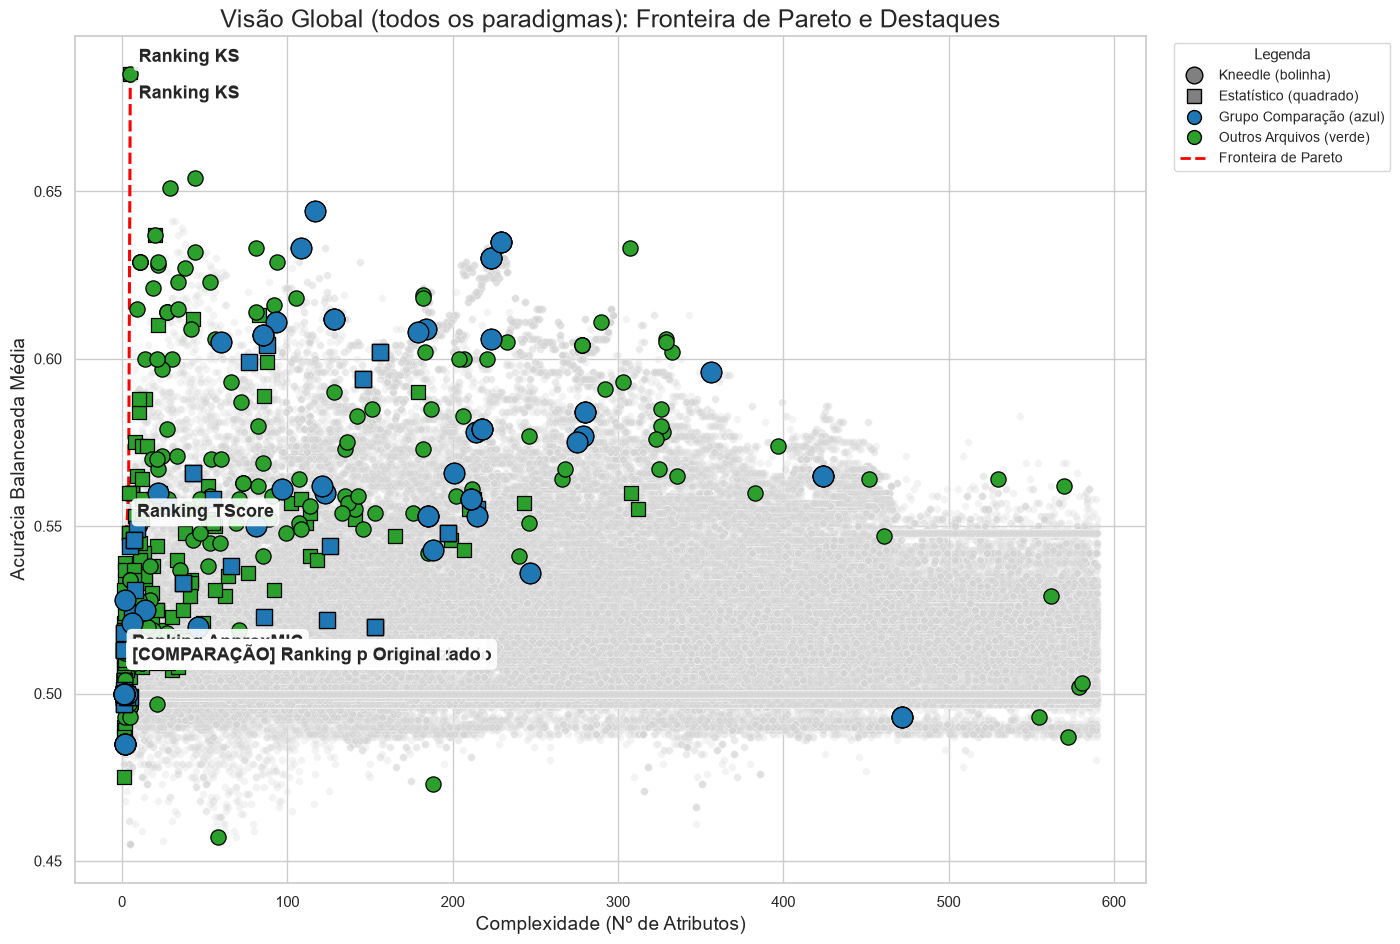

Gráfico gerado: Analise_Global_Pareto_Destaque_20261023_124611.png

Gerando gráficos individuais para 7 paradigma(s): ['DT', 'GB', 'GNB', 'LogReg_Lasso', 'MLP', 'RF', 'SVM']


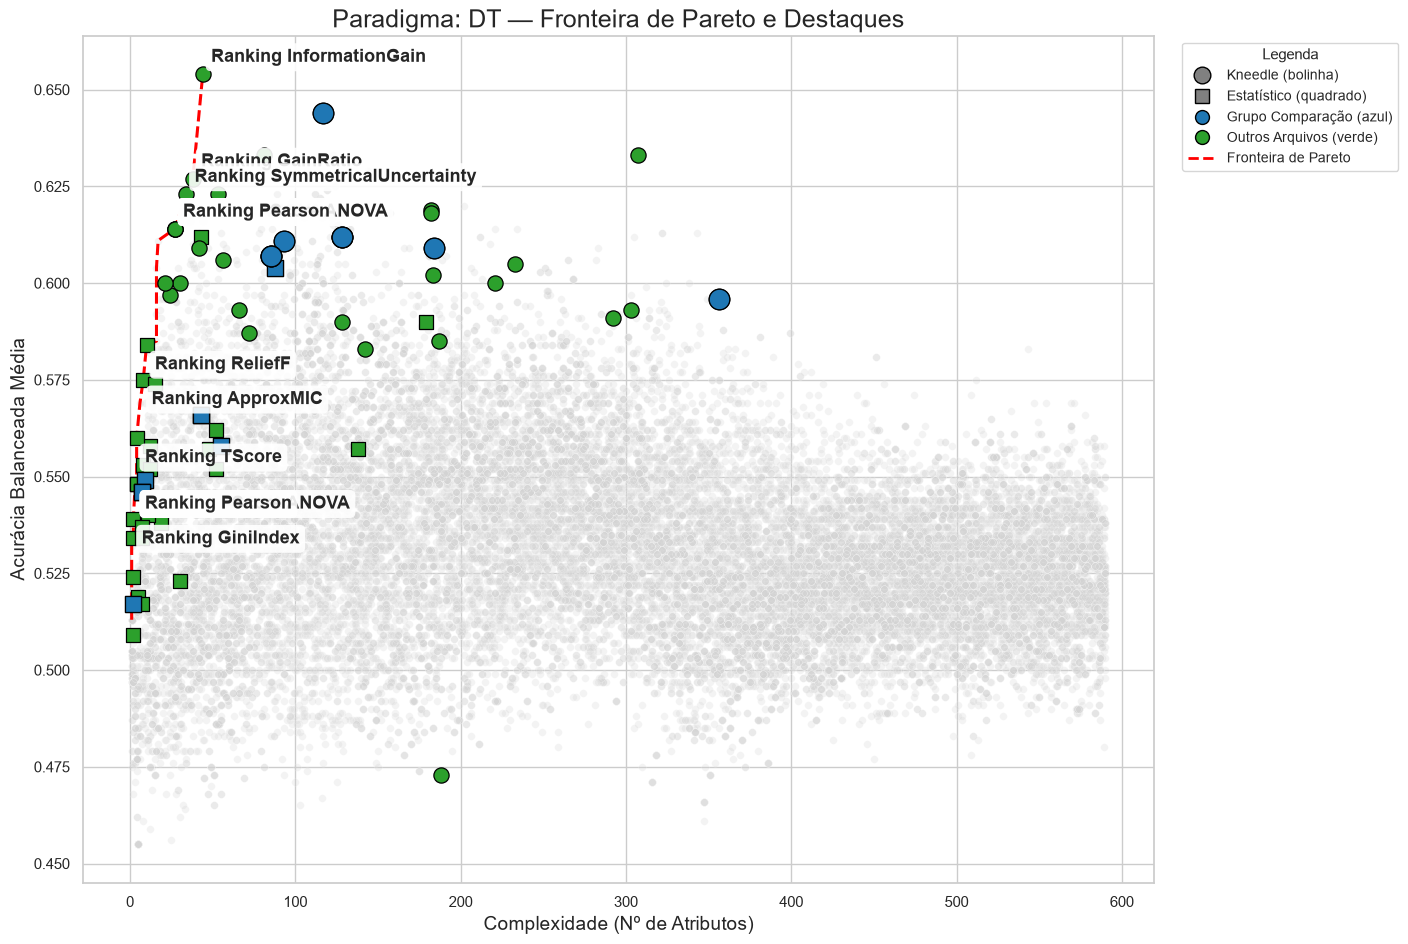

Gráfico gerado: Analise_Paradigma_DT_Pareto_Destaque_20261023_124618.png


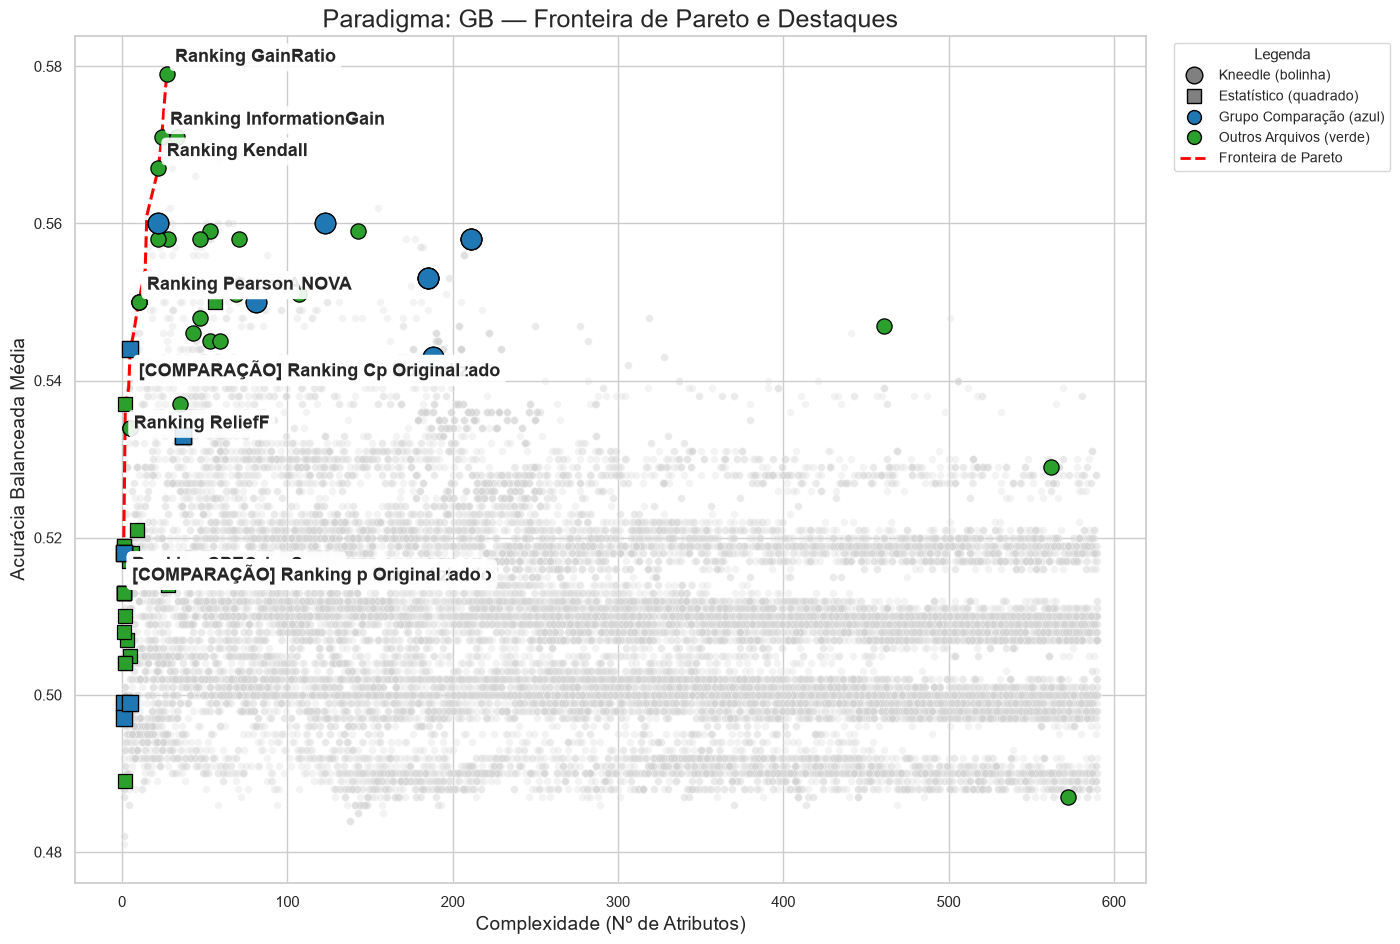

Gráfico gerado: Analise_Paradigma_GB_Pareto_Destaque_20261023_124621.png


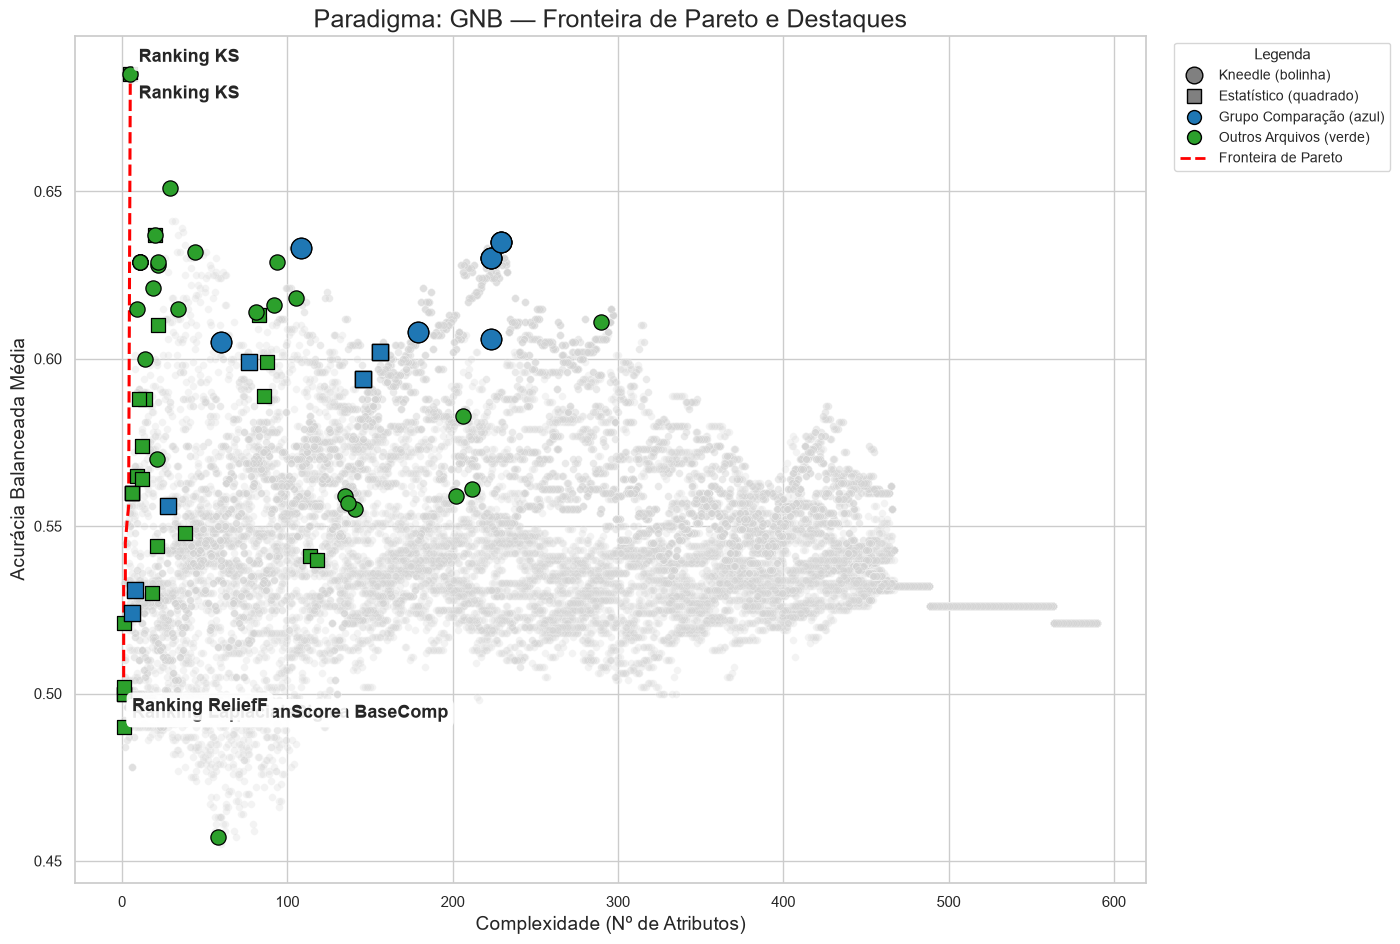

Gráfico gerado: Analise_Paradigma_GNB_Pareto_Destaque_20261023_124625.png


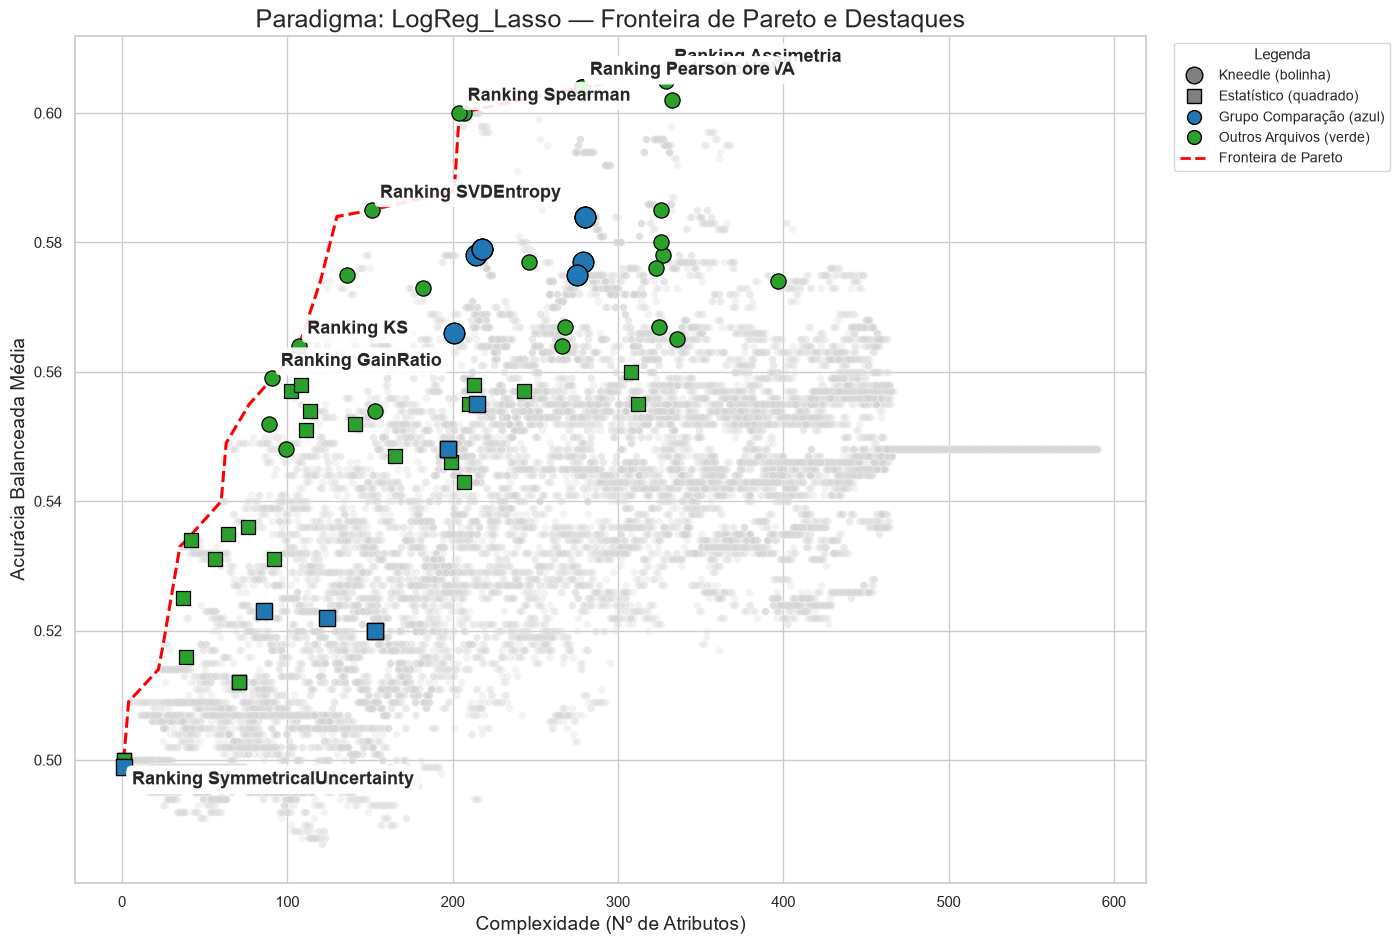

Gráfico gerado: Analise_Paradigma_LogReg_Lasso_Pareto_Destaque_20261023_124628.png


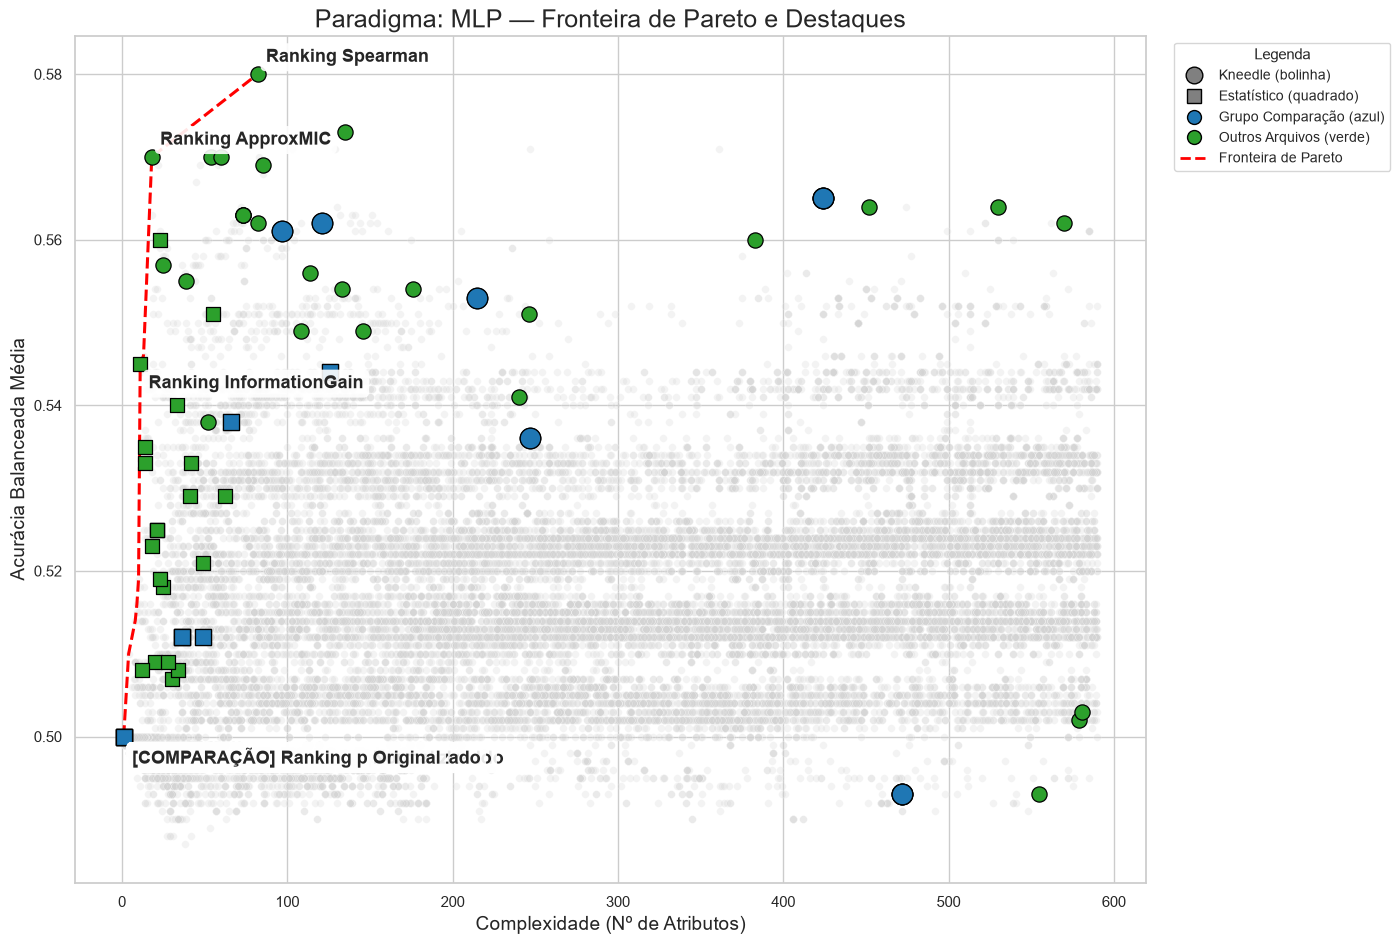

Gráfico gerado: Analise_Paradigma_MLP_Pareto_Destaque_20261023_124630.png


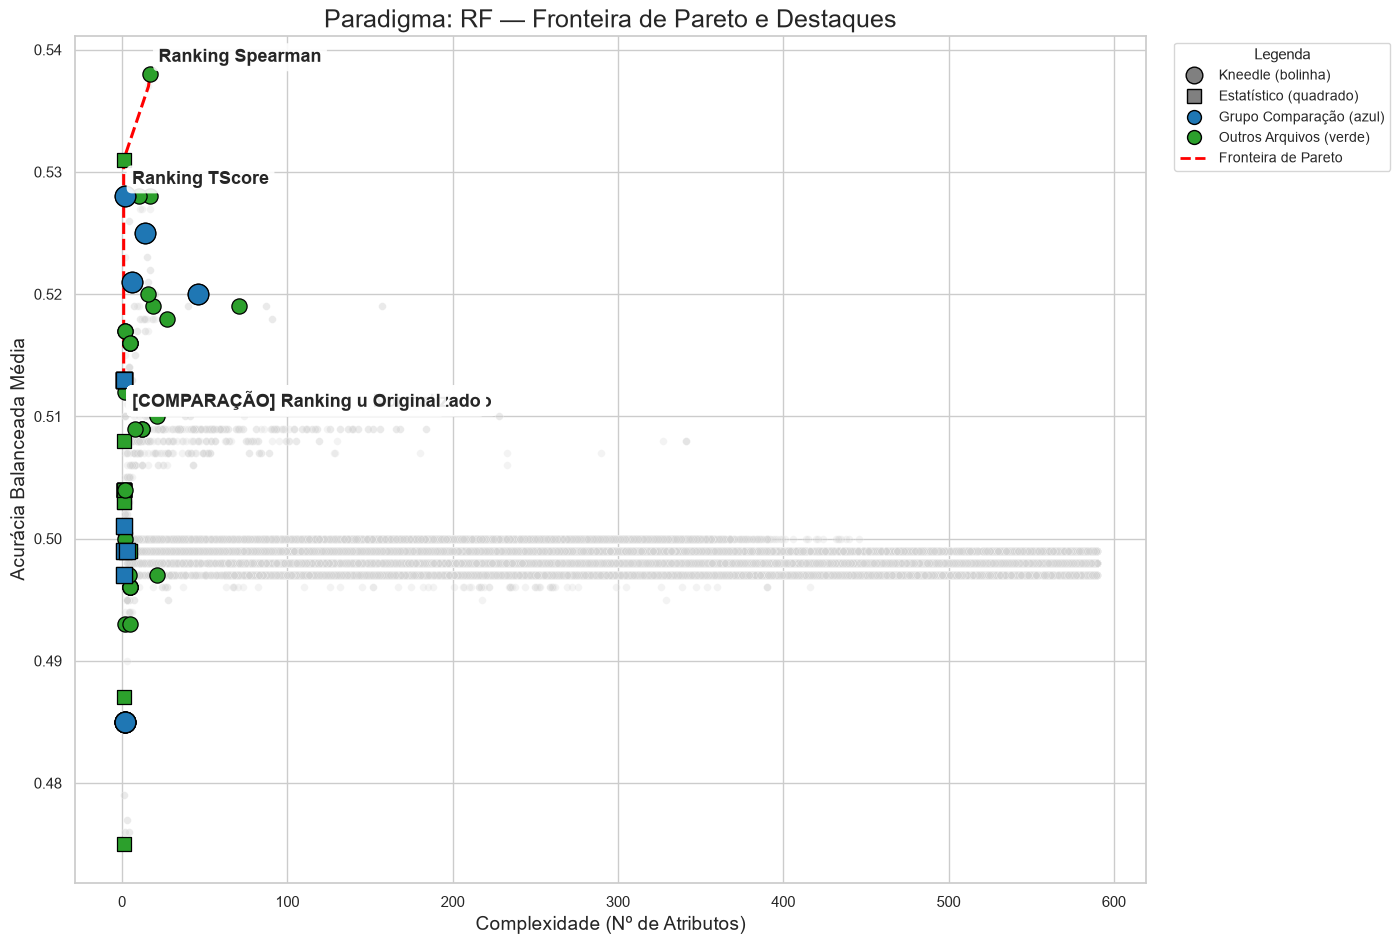

Gráfico gerado: Analise_Paradigma_RF_Pareto_Destaque_20261023_124633.png


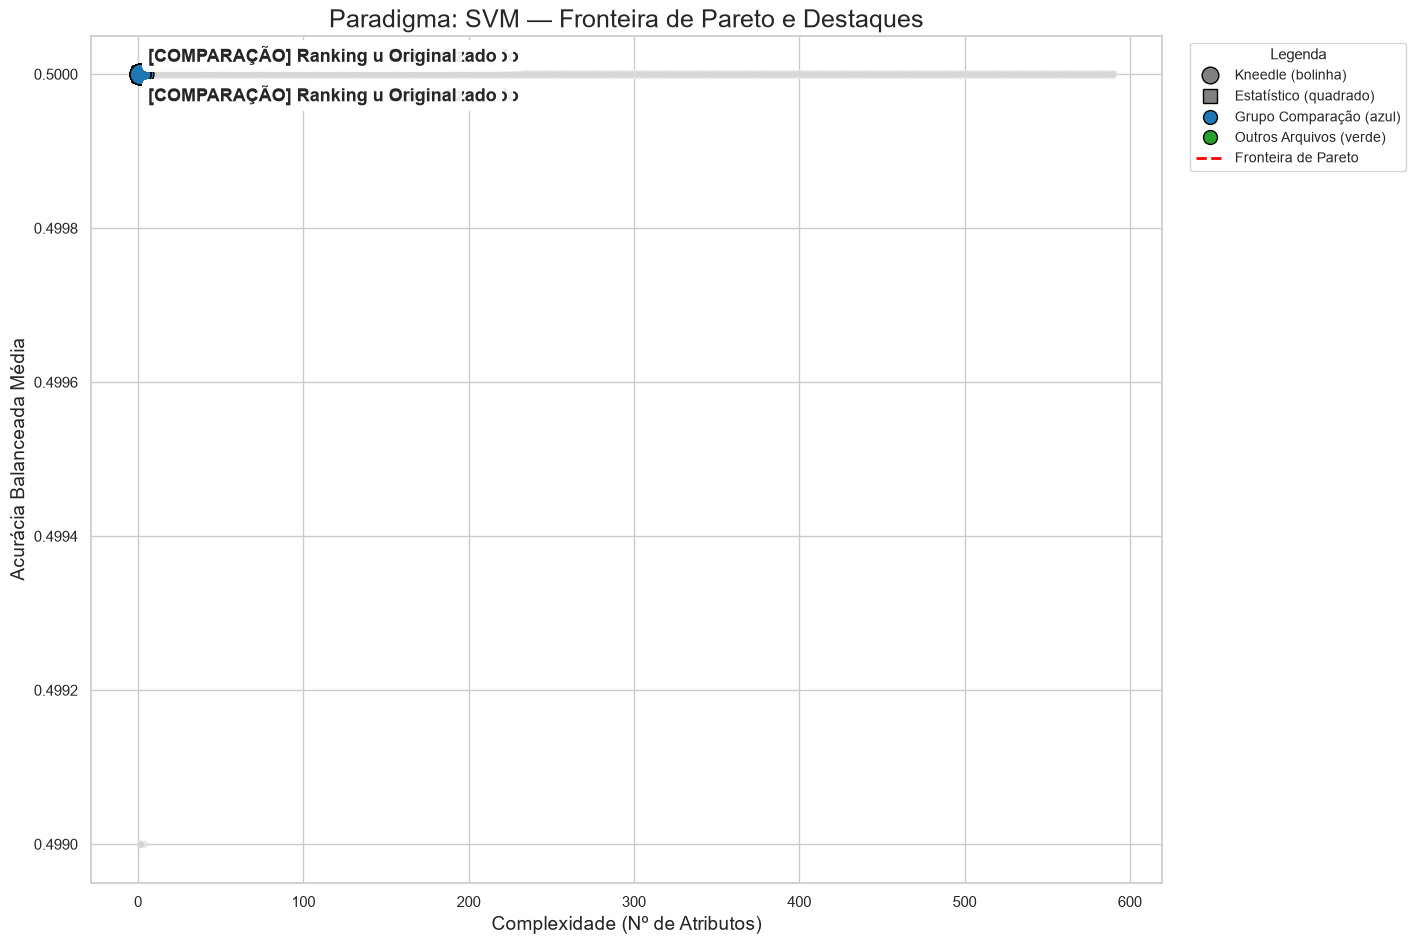

Gráfico gerado: Analise_Paradigma_SVM_Pareto_Destaque_20261023_124636.png

Resumo salvo: Resumo_Global_Dados_20261023_124639.xlsx


In [5]:
df_all, df_high = ler_curvas()

if df_all is None:
    print("Nenhum dado válido encontrado.")
else:
    # 🌐 Gráfico GLOBAL (todos os paradigmas juntos)
    plot_analysis_colored(
        df_all, df_high,
        titulo="Visão Global (todos os paradigmas): Fronteira de Pareto e Destaques",
        nome_arquivo_base="Analise_Global_Pareto_Destaque"
    )

    # 🧩 Um gráfico por paradigma
    paradigmas = sorted(df_all["Paradigma"].unique())
    print(f"\nGerando gráficos individuais para {len(paradigmas)} paradigma(s): {paradigmas}")

    for paradigma in paradigmas:
        df_all_p = df_all[df_all["Paradigma"] == paradigma]
        df_high_p = df_high[df_high["Paradigma"] == paradigma]

        if df_all_p.empty or df_high_p.empty:
            continue

        plot_analysis_colored(
            df_all_p, df_high_p,
            titulo=f"Paradigma: {paradigma} — Fronteira de Pareto e Destaques",
            nome_arquivo_base=f"Analise_Paradigma_{paradigma}_Pareto_Destaque"
        )

    # Resumo consolidado (global + por paradigma, para referência)
    timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
    resumo_filename = f"Resumo_Global_Dados_{timestamp}.xlsx"
    df_high.to_excel(resumo_filename, index=False)
    print(f"\nResumo salvo: {resumo_filename}")


### 6. Tabela consolidada (estilo "Table 14") e exportação para LaTeX

Agrupa os pontos destacados (Kneedle/Estatístico) por **Paradigma × Abordagem × Estratégia**, onde Abordagem é `Proposed` (rankings CEQ: Cp, Cpk, Pp, Ppk, p, np, c, u) ou `Literature` (todos os demais métodos), e calcula a **média** de cada métrica dentro de cada grupo -- exatamente as 4 combinações (`Literature+Statistical`, `Literature+Kneedle`, `Proposed+Statistical`, `Proposed+Kneedle`) para cada paradigma, replicando a estrutura da tabela de referência.

**Regra de negrito**: dentro de cada coluna (paradigma), compara `Literature` vs. `Proposed` **dentro da mesma estratégia** (Statistical com Statistical; Kneedle com Kneedle) e destaca em negrito o melhor dos dois: menor valor para Feature Qty. (menos atributos = mais eficiente) e maior valor para Sensitivity/Specificity/AUC-ROC (%).

In [6]:
METRICAS_TABELA = [
    ("Feature Qty. (Mean)", "Nº de Atributos", False, 1),          # (rótulo, coluna fonte, é percentual, casas decimais)
    ("Sensitivity (%)", "Sensibilidade Média", True, 2),
    ("Specificity (%)", "Especificidade Média", True, 2),
    ("AUC-ROC (%)", "AUC Média", True, 2),
]

ORDEM_PARADIGMAS = ["DT", "RF", "GB", "SVM", "MLP", "GNB", "LogReg_Lasso"]
ORDEM_APPROACH_TIPO = [
    ("Literature", "Estatístico", "Literature + Statistical"),
    ("Literature", "Kneedle", "Literature + Kneedle"),
    ("Proposed", "Estatístico", "Proposed + Statistical"),
    ("Proposed", "Kneedle", "Proposed + Kneedle"),
]

if df_high is None:
    print("Sem dados (df_high vazio) -- rode a célula de leitura/processamento antes.")
else:
    df_tab = df_high.copy()
    df_tab["Approach"] = df_tab["Ranking"].apply(lambda nome: "Proposed" if is_target_file(nome) else "Literature")

    paradigmas_presentes = [p for p in ORDEM_PARADIGMAS if p in df_tab["Paradigma"].unique()]
    # Qualquer paradigma presente nos arquivos mas ausente de ORDEM_PARADIGMAS (ex.: um 8º
    # paradigma novo, ainda não cadastrado na lista) entra no final, em vez de ser
    # descartado silenciosamente -- foi exatamente isso que aconteceu com o LogReg_Lasso.
    extras = sorted(p for p in df_tab["Paradigma"].unique() if p not in ORDEM_PARADIGMAS)
    if extras:
        print(f"Paradigma(s) fora de ORDEM_PARADIGMAS, acrescentado(s) ao final: {extras}")
        paradigmas_presentes += extras

    # --- Monta a matriz de valores (média por grupo) ---
    valores = {}   # (metric_label, approach_tipo_label) -> {paradigma: valor}
    for metric_label, col_fonte, is_percent, casas in METRICAS_TABELA:
        for approach, tipo, approach_tipo_label in ORDEM_APPROACH_TIPO:
            linha = {}
            for paradigma in paradigmas_presentes:
                grupo = df_tab[
                    (df_tab["Paradigma"] == paradigma) &
                    (df_tab["Approach"] == approach) &
                    (df_tab["Tipo"] == tipo)
                ]
                if col_fonte not in df_tab.columns or grupo[col_fonte].dropna().empty:
                    linha[paradigma] = np.nan
                    continue
                media = grupo[col_fonte].mean()
                linha[paradigma] = media * 100 if is_percent else media
            valores[(metric_label, approach_tipo_label)] = linha

    # --- Tabela "achatada" para conferência/Excel ---
    linhas_flat = []
    for (metric_label, approach_tipo_label), linha in valores.items():
        registro = {"Metric": metric_label, "Approach": approach_tipo_label}
        registro.update(linha)
        linhas_flat.append(registro)
    df_tabela_consolidada = pd.DataFrame(linhas_flat)

    caminho_consolidada = os.path.join(FOLDER_PATH, f"Tabela_Consolidada_LiteratureVsProposed_{timestamp}.xlsx")
    df_tabela_consolidada.to_excel(caminho_consolidada, index=False)
    print(f"Tabela consolidada (Excel) salva em: {caminho_consolidada}")

    # --- Regra de negrito: Literature vs Proposed, dentro da mesma estratégia (Statistical/Kneedle) ---
    negrito = {}  # (metric_label, approach_tipo_label, paradigma) -> True/False
    for metric_label, col_fonte, is_percent, casas in METRICAS_TABELA:
        menor_e_melhor = (metric_label == "Feature Qty. (Mean)")
        for tipo_label_sufixo, lit_label, prop_label in [
            ("Statistical", "Literature + Statistical", "Proposed + Statistical"),
            ("Kneedle", "Literature + Kneedle", "Proposed + Kneedle"),
        ]:
            for paradigma in paradigmas_presentes:
                v_lit = valores[(metric_label, lit_label)].get(paradigma, np.nan)
                v_prop = valores[(metric_label, prop_label)].get(paradigma, np.nan)
                if pd.isna(v_lit) or pd.isna(v_prop):
                    continue
                if menor_e_melhor:
                    vencedor = lit_label if v_lit < v_prop else prop_label
                else:
                    vencedor = lit_label if v_lit > v_prop else prop_label
                negrito[(metric_label, vencedor, paradigma)] = True

    print("Regra de negrito aplicada (Literature vs. Proposed, por estratégia).")


✅ Tabela consolidada (Excel) salva em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Consolidada_LiteratureVsProposed_20261023_124639.xlsx
✅ Regra de negrito aplicada (Literature vs. Proposed, por estratégia).


### 7. Geração do código LaTeX (formato "Table 14")

In [7]:
if df_high is not None:
    def fmt(valor, casas, is_bold):
        if pd.isna(valor):
            texto = "--"
        else:
            texto = f"{valor:.{casas}f}"
        return f"\\textbf{{{texto}}}" if is_bold else texto

    linhas_latex = []
    linhas_latex.append("% Requer os pacotes: \\usepackage{booktabs} e \\usepackage{multirow}")
    linhas_latex.append("\\begin{table}[htbp]")
    linhas_latex.append("\\centering")
    linhas_latex.append("\\caption{Consolidated Quality Evaluation of Classifiers}")
    linhas_latex.append("\\label{tab:qualidade_consolidada}")
    colspec = "ll" + "c" * len(paradigmas_presentes)
    linhas_latex.append(f"\\begin{{tabular}}{{{colspec}}}")
    linhas_latex.append("\\toprule")
    header = "Metric & Approach & " + " & ".join(paradigmas_presentes) + " \\\\"
    linhas_latex.append(header)
    linhas_latex.append("\\midrule")

    for metric_label, col_fonte, is_percent, casas in METRICAS_TABELA:
        metric_label_latex = metric_label.replace("%", "\\%")  # "%" é comentário em LaTeX -- precisa escapar
        linhas_latex.append(f"\\multirow{{4}}{{*}}{{{metric_label_latex}}}")
        for approach, tipo, approach_tipo_label in ORDEM_APPROACH_TIPO:
            linha = valores[(metric_label, approach_tipo_label)]
            celulas = []
            for paradigma in paradigmas_presentes:
                v = linha.get(paradigma, np.nan)
                is_bold = negrito.get((metric_label, approach_tipo_label, paradigma), False)
                celulas.append(fmt(v, casas, is_bold))
            linha_texto = f" & {approach_tipo_label} & " + " & ".join(celulas) + " \\\\"
            linhas_latex.append(linha_texto)
        linhas_latex.append("\\midrule")

    # Remove o último \midrule sobrando e fecha a tabela
    if linhas_latex[-1] == "\\midrule":
        linhas_latex.pop()
    linhas_latex.append("\\bottomrule")
    linhas_latex.append("\\end{tabular}")
    linhas_latex.append("\\end{table}")

    codigo_latex = "\n".join(linhas_latex)

    caminho_tex = os.path.join(FOLDER_PATH, f"Tabela_Consolidada_LiteratureVsProposed_{timestamp}.tex")
    with open(caminho_tex, "w", encoding="utf-8") as f:
        f.write(codigo_latex)

    print(f"Código LaTeX salvo em: {caminho_tex}\n")
    print(codigo_latex)


✅ Código LaTeX salvo em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Consolidada_LiteratureVsProposed_20261023_124639.tex

% Requer os pacotes: \usepackage{booktabs} e \usepackage{multirow}
\begin{table}[htbp]
\centering
\caption{Consolidated Quality Evaluation of Classifiers}
\label{tab:qualidade_consolidada}
\begin{tabular}{llccccccc}
\toprule
Metric & Approach & DT & RF & GB & SVM & MLP & GNB & LogReg_Lasso \\
\midrule
\multirow{4}{*}{Feature Qty. (Mean)}
 & Literature + Statistical & \textbf{25.4} & 1.3 & \textbf{6.8} & \textbf{1.1} & \textbf{22.3} & \textbf{26.1} & \textbf{115.8} \\
 & Literature + Kneedle & \textbf{118.1} & 11.4 & \textbf{103.3} & \textbf{1.1} & \textbf{209.8} & \textbf{75.4} & 246.7 \\
 & Proposed + Statistical & 31.8 & \textbf{1.2} & 11.0 & 1.2 & 39.5 & 90.4 & 140.8 \\
 & Proposed + Kneedle & 147.0 & \textbf{9.5} & 150.8 & 1.2 & 309.0 & 184.2 & \textbf{245.6} \\
\midrule
\multirow{4}{*}{Sensitivity (\%)}
 & Literature + Statistical & 16.76 &

### 8. Mann-Whitney: Proposed vs. Literature

*"Proposed" é significativamente melhor que "Literature", ou a diferença observada pode ser só ruído entre métodos?*

**Por que Mann-Whitney (não-pareado) em vez de Wilcoxon pareado por fold**: o Wilcoxon pareado, fold a fold, tem um piso matemático: com apenas 5 folds, o teste exato nunca consegue chegar a p ≤ 0,05, não importa o tamanho da diferença real (o menor p-valor possível com n=5 é 0,0625). Agrupar todos os valores de fold de todos os métodos (8 do CEQ × 5 folds = 40; ~20 da Literatura × 5 folds = 100) resolveria o piso, mas violaria a suposição de independência do teste — os 5 folds de métodos diferentes vêm da mesma divisão de dados (`random_state=42` fixo), então não são observações independentes (pseudorreplicação).

**O meio-termo adotado**: cada MÉTODO (não cada fold) vira uma observação. Para cada (Paradigma, Estratégia [Kneedle/Estatístico], Métrica), calcula a média dos 5 folds de cada método -- já disponível na coluna `<Métrica> Média` de cada linha destacada -- e roda o Mann-Whitney entre o grupo de médias do CEQ (n≈8) e o grupo de médias da Literatura (n≈20). Isso dá poder estatístico real (piso do p-valor ~10⁻⁷ com 8 vs. 20) sem inflar artificialmente a amostra com folds correlacionados.

*Isso responde a uma pergunta um pouco diferente da versão pareada: "o conjunto de métodos do CEQ tende a ter desempenho maior que o conjunto da Literatura?", em vez de "fold a fold, o CEQ vence?" -- mas é uma pergunta legítima e mais próxima do que o resumo do artigo já afirma.*

In [8]:
from scipy.stats import mannwhitneyu

METRICAS_MANNWHITNEY = [
    ("Acurácia Balanceada Média", "Acurácia Balanceada"),
    ("Sensibilidade Média", "Sensibilidade"),
    ("Especificidade Média", "Especificidade"),
    ("AUC Média", "AUC"),
]

if df_high is None:
    print("Sem dados (df_high vazio) -- rode a célula de leitura/processamento antes.")
else:
    registros_sig = []
    for paradigma in paradigmas_presentes:
        for tipo in ["Kneedle", "Estatístico"]:
            df_p_t = df_tab[(df_tab["Paradigma"] == paradigma) & (df_tab["Tipo"] == tipo)]
            df_prop = df_p_t[df_p_t["Approach"] == "Proposed"]
            df_lit = df_p_t[df_p_t["Approach"] == "Literature"]

            for col_media, rotulo_metrica in METRICAS_MANNWHITNEY:
                if col_media not in df_p_t.columns:
                    continue

                grupo_prop = df_prop[col_media].dropna().values  # 1 valor por método (n≈8)
                grupo_lit = df_lit[col_media].dropna().values    # 1 valor por método (n≈20)

                if len(grupo_prop) < 1 or len(grupo_lit) < 1:
                    p_valor, sig = np.nan, False
                elif len(grupo_prop) == 1 and len(grupo_lit) == 1:
                    # Mann-Whitney não é informativo com 1 observação de cada lado
                    p_valor, sig = np.nan, False
                else:
                    try:
                        _, p_valor = mannwhitneyu(grupo_prop, grupo_lit, alternative="two-sided")
                        sig = bool(p_valor <= 0.05)
                    except ValueError:
                        p_valor, sig = np.nan, False

                media_prop = float(np.mean(grupo_prop)) if len(grupo_prop) else np.nan
                media_lit = float(np.mean(grupo_lit)) if len(grupo_lit) else np.nan

                registros_sig.append({
                    "Paradigma": paradigma,
                    "Estratégia": tipo,
                    "Métrica": rotulo_metrica,
                    "N Métodos Proposed": len(grupo_prop),
                    "N Métodos Literature": len(grupo_lit),
                    "Média Proposed": round(media_prop, 4) if not pd.isna(media_prop) else np.nan,
                    "Média Literature": round(media_lit, 4) if not pd.isna(media_lit) else np.nan,
                    "p-valor (Mann-Whitney)": round(float(p_valor), 4) if not pd.isna(p_valor) else np.nan,
                    "Diferença Significativa (p<=0.05)": sig,
                    "Quem Venceu": (
                        "Proposed" if (not pd.isna(media_prop) and not pd.isna(media_lit) and media_prop > media_lit)
                        else "Literature" if not pd.isna(media_lit) else "--"
                    ),
                })

    df_significancia = pd.DataFrame(registros_sig)
    caminho_sig = os.path.join(FOLDER_PATH, f"CODE5_Significancia_PropostoVsLiteratura_{timestamp}.xlsx")
    df_significancia.to_excel(caminho_sig, index=False)

    n_testado = df_significancia["p-valor (Mann-Whitney)"].notna().sum()
    n_sig = df_significancia["Diferença Significativa (p<=0.05)"].sum()
    print(f"{n_sig} de {n_testado} comparações com diferença estatisticamente significativa (p ≤ 0,05).")
    print(f"Salvo: {caminho_sig}\n")

    if n_testado == 0:
        print("Nenhuma comparação pôde ser testada -- confira se há métodos 'Proposed' e "
              "'Literature' suficientes (pelo menos 2 de cada lado) para cada paradigma/estratégia.")
    else:
        print(df_significancia.to_string(index=False))

✅ 13 de 50 comparações com diferença estatisticamente significativa (p ≤ 0,05).
✅ Salvo: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\CODE5_Significancia_PropostoVsLiteratura_20261023_124639.xlsx

   Paradigma  Estratégia             Métrica  N Métodos Proposed  N Métodos Literature  Média Proposed  Média Literature  p-valor (Mann-Whitney)  Diferença Significativa (p<=0.05) Quem Venceu
          DT     Kneedle Acurácia Balanceada                  16                    27          0.6122            0.6032                  0.3327                              False    Proposed
          DT     Kneedle       Sensibilidade                  16                    27          0.2893            0.2760                  0.3195                              False    Proposed
          DT     Kneedle      Especificidade                  16                    27          0.9347            0.9304                  0.2519                              False    Proposed
          DT     Kneedl

### 9. Tabela de custo computacional (escalabilidade)

Para cada `Modelos<Paradigma>_CV_<Ranking>.xlsx` (curva inteira do Backward Elimination), ajusta uma regressão log-log entre `Nº de Atributos` (N) e `Tempo de Execução (s)` (T): $T = c \cdot N^\alpha$, ou seja, $\log(T) = \log(c) + \alpha \log(N)$. Extrai quatro indicadores por ranking:

- **Scalability (α)**: a inclinação da reta em escala log-log. **Menor é melhor** — α mais baixo indica crescimento mais sublinear do tempo conforme mais atributos são adicionados (mais escalável).
- **Reliability (r)**: correlação de Pearson do ajuste log-log. **Maior é melhor** — indica o quanto a curva real se comporta como uma lei de potência (quão confiável é o α extraído).
- **Mean Time (s)**: tempo médio de execução ao longo de toda a curva. **Menor é melhor.**
- **Efficiency (s/feat.)**: tempo dividido pelo número de atributos, em média ao longo da curva (T/N). **Menor é melhor.**

**Regra de negrito, documentada e simétrica**: em cada célula, compara Proposed vs. Literature e destaca em negrito **quem tiver o valor melhor**, não importa o lado -- usando a direção "menor/maior é melhor" de cada métrica, listada acima.

Como na seção 4, cada arquivo `Modelos<Paradigma>_CV_Consolidado.xlsx` tem 1 aba por ranking, e a regressão log-log é ajustada aba a aba (cada aba é a curva completa de um ranking).

In [9]:
from scipy.stats import linregress

def calcular_escalabilidade(df):
    '''Ajusta T = c*N^alpha (log-log) sobre a curva inteira de um ranking (uma aba do
    Modelos<Paradigma>_CV_Consolidado.xlsx). Recebe o DataFrame já lido (cada aba chega como DataFrame, lido 1 vez por arquivo).'''
    if "Nº de Atributos" not in df.columns or "Tempo de Execução (s)" not in df.columns:
        return None
    df = df[(df["Nº de Atributos"] > 0) & (df["Tempo de Execução (s)"] > 0)]
    if len(df) < 3:  # regressão precisa de pelo menos 3 pontos pra ser minimamente confiável
        return None

    log_n = np.log(df["Nº de Atributos"].values)
    log_t = np.log(df["Tempo de Execução (s)"].values)
    slope, intercept, r_value, p_value, std_err = linregress(log_n, log_t)

    return {
        "Scalability (alpha)": slope,
        "Reliability (r)": r_value,
        "Mean Time (s)": df["Tempo de Execução (s)"].mean(),
        "Efficiency (s/feat.)": (df["Tempo de Execução (s)"] / df["Nº de Atributos"]).mean(),
        "N Pontos Curva": len(df),
    }


arquivos_consolidados_custo = sorted(glob.glob(os.path.join(FOLDER_PATH, FILE_PATTERN)))

registros_custo = []
for arquivo in arquivos_consolidados_custo:
    nome_arquivo = os.path.basename(arquivo)
    paradigma = extrair_paradigma(nome_arquivo)

    try:
        todas_as_abas = pd.read_excel(arquivo, sheet_name=None)
    except Exception as e:
        print(f"Erro ao abrir '{nome_arquivo}': {e}")
        continue

    for nome_ranking, df_aba in todas_as_abas.items():
        resultado = calcular_escalabilidade(df_aba)
        if resultado is None:
            print(f"Aba '{nome_ranking}' de '{nome_arquivo}' sem pontos suficientes para "
                  f"regressão. Ignorada.")
            continue

        registros_custo.append({
            "Paradigma": paradigma,
            "Ranking": nome_ranking,
            "Approach": "Proposed" if is_target_file(nome_ranking) else "Literature",
            **resultado,
        })

df_custo_bruto = pd.DataFrame(registros_custo)
caminho_custo_bruto = os.path.join(FOLDER_PATH, f"CODE9_Escalabilidade_Por_Ranking_{timestamp}.xlsx")
df_custo_bruto.to_excel(caminho_custo_bruto, index=False)
print(f"{len(df_custo_bruto)} curva(s) processada(s) (regressão log-log).")
print(f"Salvo: {caminho_custo_bruto}")


✅ 301 curva(s) processada(s) (regressão log-log).
✅ Salvo: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\CODE9_Escalabilidade_Por_Ranking_20261023_124639.xlsx


#### 9.1 Agregação Proposed vs. Literature, com teste de significância (Mann-Whitney)

Mesma lógica da seção 8: cada ranking (não cada fold) é uma observação, então Proposed tem n≈8 e Literature n≈20 -- poder estatístico real, sem pseudorreplicação.

In [10]:
METRICAS_CUSTO = [
    ("Mean Time (s)", True),           # (coluna, menor_e_melhor)
    ("Scalability (alpha)", True),
    ("Reliability (r)", False),
    ("Efficiency (s/feat.)", True),
]

if df_custo_bruto.empty:
    print("Sem dados de custo -- rode a célula anterior primeiro.")
else:
    paradigmas_custo = [p for p in ORDEM_PARADIGMAS if p in df_custo_bruto["Paradigma"].unique()]

    valores_custo = {}     # (metric, approach) -> {paradigma: valor}
    significancia_custo = []

    for col_metrica, menor_e_melhor in METRICAS_CUSTO:
        for approach in ["Literature", "Proposed"]:
            linha = {}
            for paradigma in paradigmas_custo:
                grupo = df_custo_bruto[
                    (df_custo_bruto["Paradigma"] == paradigma) & (df_custo_bruto["Approach"] == approach)
                ][col_metrica].dropna()
                linha[paradigma] = grupo.mean() if not grupo.empty else np.nan
            valores_custo[(col_metrica, approach)] = linha

        for paradigma in paradigmas_custo:
            grupo_prop = df_custo_bruto[
                (df_custo_bruto["Paradigma"] == paradigma) & (df_custo_bruto["Approach"] == "Proposed")
            ][col_metrica].dropna().values
            grupo_lit = df_custo_bruto[
                (df_custo_bruto["Paradigma"] == paradigma) & (df_custo_bruto["Approach"] == "Literature")
            ][col_metrica].dropna().values

            if len(grupo_prop) < 2 or len(grupo_lit) < 2:
                p_valor, sig = np.nan, False
            else:
                try:
                    _, p_valor = mannwhitneyu(grupo_prop, grupo_lit, alternative="two-sided")
                    sig = bool(p_valor <= 0.05)
                except ValueError:
                    p_valor, sig = np.nan, False

            significancia_custo.append({
                "Paradigma": paradigma, "Métrica": col_metrica,
                "N Proposed": len(grupo_prop), "N Literature": len(grupo_lit),
                "Média Proposed": round(float(np.mean(grupo_prop)), 4) if len(grupo_prop) else np.nan,
                "Média Literature": round(float(np.mean(grupo_lit)), 4) if len(grupo_lit) else np.nan,
                "p-valor (Mann-Whitney)": round(float(p_valor), 4) if not pd.isna(p_valor) else np.nan,
                "Diferença Significativa (p<=0.05)": sig,
            })

    df_sig_custo = pd.DataFrame(significancia_custo)
    caminho_sig_custo = os.path.join(FOLDER_PATH, f"CODE9_Significancia_Custo_{timestamp}.xlsx")
    df_sig_custo.to_excel(caminho_sig_custo, index=False)

    # --- Regra de negrito: SIMÉTRICA -- vence quem tiver o valor melhor, seja qual for o lado ---
    negrito_custo = {}  # (metric, approach, paradigma) -> True/False
    for col_metrica, menor_e_melhor in METRICAS_CUSTO:
        for paradigma in paradigmas_custo:
            v_lit = valores_custo[(col_metrica, "Literature")].get(paradigma, np.nan)
            v_prop = valores_custo[(col_metrica, "Proposed")].get(paradigma, np.nan)
            if pd.isna(v_lit) or pd.isna(v_prop):
                continue
            if menor_e_melhor:
                vencedor = "Literature" if v_lit < v_prop else "Proposed"
            else:
                vencedor = "Literature" if v_lit > v_prop else "Proposed"
            negrito_custo[(col_metrica, vencedor, paradigma)] = True

    n_sig = df_sig_custo["Diferença Significativa (p<=0.05)"].sum()
    print(f"Tabela de custo agregada. {n_sig} de {len(df_sig_custo)} comparações estatisticamente significativas.")
    print(f"Salvo: {caminho_sig_custo}\n")
    print(df_sig_custo.to_string(index=False))

✅ Tabela de custo agregada. 4 de 28 comparações estatisticamente significativas.
✅ Salvo: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\CODE9_Significancia_Custo_20261023_124639.xlsx

   Paradigma              Métrica  N Proposed  N Literature  Média Proposed  Média Literature  p-valor (Mann-Whitney)  Diferença Significativa (p<=0.05)
          DT        Mean Time (s)          16            27          2.6805            2.4316                  0.0059                               True
          RF        Mean Time (s)          16            27          7.9500            8.1278                  0.3724                              False
          GB        Mean Time (s)          16            27         37.4517           33.9886                  0.4896                              False
         SVM        Mean Time (s)          16            27          3.4012            3.3329                  0.2635                              False
         MLP        Mean Time (s)       

### 10. Exportação final: Tabela de Custo e Tabela de Qualidade (LaTeX, com † de significância)

Reaproveita a Tabela 14 (qualidade, seção 6) e a tabela de custo (seção 9), adicionando um **†** ao lado do valor sempre que a diferença Proposed vs. Literature naquela célula for estatisticamente significativa (Mann-Whitney, p ≤ 0,05) -- cruzando com os resultados já calculados nas seções 8 (qualidade) e 9.1 (custo). Negrito continua marcando só quem numericamente venceu; o † marca quando essa vitória é estatisticamente sustentada.

In [11]:
def fmt_com_significancia(valor, casas, is_bold, is_sig):
    if pd.isna(valor):
        texto = "--"
    else:
        texto = f"{valor:.{casas}f}"
        if is_sig:
            texto += "$^\\dagger$"
    return f"\\textbf{{{texto}}}" if is_bold else texto


# --- Tabela de custo ---
def sig_custo_lookup(metric_label, approach_label, paradigma):
    linha = df_sig_custo[(df_sig_custo["Métrica"] == metric_label) & (df_sig_custo["Paradigma"] == paradigma)]
    if linha.empty:
        return False
    return bool(linha.iloc[0]["Diferença Significativa (p<=0.05)"])

partes_custo = []
partes_custo.append("% Requer \\usepackage{booktabs}, \\usepackage{multirow}, \\usepackage{amssymb}")
partes_custo.append("\\begin{table}[htbp]")
partes_custo.append("\\centering")
partes_custo.append("\\caption{Consolidated Comparison of Computational Efficiency and Scalability}")
partes_custo.append("\\label{tab:custo_consolidado}")
partes_custo.append("\\begin{tabular}{ll" + "c" * len(paradigmas_custo) + "}")
partes_custo.append("\\toprule")
partes_custo.append("Metric & Approach & " + " & ".join(paradigmas_custo) + " \\\\")
partes_custo.append("\\midrule")
for col_metrica, menor_e_melhor in METRICAS_CUSTO:
    casas = 2 if col_metrica != "Efficiency (s/feat.)" else 3
    partes_custo.append(f"\\multirow{{2}}{{*}}{{{col_metrica}}}")
    for approach_label, approach_chave in [("Literature (Standard)", "Literature"), ("Proposed (Target)", "Proposed")]:
        celulas = []
        for paradigma in paradigmas_custo:
            v = valores_custo[(col_metrica, approach_chave)].get(paradigma, np.nan)
            is_bold = negrito_custo.get((col_metrica, approach_chave, paradigma), False)
            is_sig = sig_custo_lookup(col_metrica, approach_label, paradigma)
            celulas.append(fmt_com_significancia(v, casas, is_bold, is_sig))
        partes_custo.append(f" & {approach_label} & " + " & ".join(celulas) + " \\\\")
    partes_custo.append("\\midrule")
if partes_custo[-1] == "\\midrule":
    partes_custo.pop()
partes_custo.append("\\bottomrule")
partes_custo.append("\\end{tabular}")
partes_custo.append("\\vspace{2pt}\\\\")
partes_custo.append("{\\footnotesize $^\\dagger$ Diferença estatisticamente significativa (Mann-Whitney, "
                     "$p \\leq 0{,}05$), um ranking = uma observação.}")
partes_custo.append("\\end{table}")
codigo_latex_custo = "\n".join(partes_custo)

caminho_tex_custo = os.path.join(FOLDER_PATH, f"Tabela_Custo_Computacional_{timestamp}.tex")
with open(caminho_tex_custo, "w", encoding="utf-8") as f:
    f.write(codigo_latex_custo)
print(f"Tabela de custo (LaTeX) salva em: {caminho_tex_custo}\n")
print(codigo_latex_custo)

✅ Tabela de custo (LaTeX) salva em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Custo_Computacional_20261023_124639.tex

% Requer \usepackage{booktabs}, \usepackage{multirow}, \usepackage{amssymb}
\begin{table}[htbp]
\centering
\caption{Consolidated Comparison of Computational Efficiency and Scalability}
\label{tab:custo_consolidado}
\begin{tabular}{llccccccc}
\toprule
Metric & Approach & DT & RF & GB & SVM & MLP & GNB & LogReg_Lasso \\
\midrule
\multirow{2}{*}{Mean Time (s)}
 & Literature (Standard) & \textbf{2.43$^\dagger$} & 8.13 & \textbf{33.99} & \textbf{3.33} & 12.63 & 0.51 & 2.37 \\
 & Proposed (Target) & 2.68$^\dagger$ & \textbf{7.95} & 37.45 & 3.40 & \textbf{12.58} & \textbf{0.51} & \textbf{2.31} \\
\midrule
\multirow{2}{*}{Scalability (alpha)}
 & Literature (Standard) & \textbf{0.78$^\dagger$} & 0.25 & \textbf{0.82} & 0.64 & 0.29 & \textbf{0.47} & 0.71 \\
 & Proposed (Target) & 0.80$^\dagger$ & \textbf{0.25} & 0.83 & \textbf{0.64} & \textbf{0.28} & 0.48 & 

#### 10.1 Tabela de Qualidade (Tabela 14) com †

Mesmo princípio, aplicado à tabela de qualidade da seção 6/7: reaproveita `valores` e `negrito` (já calculados lá) e cruza com `df_significancia` (seção 8) para acrescentar o † nas células cuja diferença Proposed vs. Literature for estatisticamente significativa.

In [12]:
def sig_qualidade_lookup(metric_label, approach_tipo_label, paradigma):
    """approach_tipo_label é algo como 'Literature + Statistical' -- separa em Approach e Estratégia
    para casar com as colunas de df_significancia (seção 8)."""
    if "Kneedle" in approach_tipo_label:
        estrategia = "Kneedle"
    elif "Statistical" in approach_tipo_label:
        estrategia = "Estatístico"
    else:
        return False

    # metric_label aqui é o rótulo "de exibição" (ex.: "Sensitivity (%)"); mapeia pro
    # nome usado em METRICAS_MANNWHITNEY / df_significancia
    mapa_metrica = {
        "Sensitivity (%)": "Sensibilidade",
        "Specificity (%)": "Especificidade",
        "AUC-ROC (%)": "AUC",
        "Feature Qty. (Mean)": None,  # não faz parte do teste de significância (é contagem, não desempenho)
    }
    metrica_teste = mapa_metrica.get(metric_label)
    if metrica_teste is None:
        return False

    linha = df_significancia[
        (df_significancia["Paradigma"] == paradigma) &
        (df_significancia["Estratégia"] == estrategia) &
        (df_significancia["Métrica"] == metrica_teste)
    ]
    if linha.empty:
        return False
    return bool(linha.iloc[0]["Diferença Significativa (p<=0.05)"])


partes_qual = []
partes_qual.append("% Requer \\usepackage{booktabs}, \\usepackage{multirow}, \\usepackage{amssymb}")
partes_qual.append("\\begin{table}[htbp]")
partes_qual.append("\\centering")
partes_qual.append("\\caption{Consolidated Quality Evaluation of Classifiers}")
partes_qual.append("\\label{tab:qualidade_consolidada_sig}")
partes_qual.append("\\begin{tabular}{ll" + "c" * len(paradigmas_presentes) + "}")
partes_qual.append("\\toprule")
partes_qual.append("Metric & Approach & " + " & ".join(paradigmas_presentes) + " \\\\")
partes_qual.append("\\midrule")

for metric_label, col_fonte, is_percent, casas in METRICAS_TABELA:
    metric_label_latex = metric_label.replace("%", "\\%")
    partes_qual.append(f"\\multirow{{4}}{{*}}{{{metric_label_latex}}}")
    for approach, tipo, approach_tipo_label in ORDEM_APPROACH_TIPO:
        linha = valores[(metric_label, approach_tipo_label)]
        celulas = []
        for paradigma in paradigmas_presentes:
            v = linha.get(paradigma, np.nan)
            is_bold = negrito.get((metric_label, approach_tipo_label, paradigma), False)
            is_sig = sig_qualidade_lookup(metric_label, approach_tipo_label, paradigma)
            celulas.append(fmt_com_significancia(v, casas, is_bold, is_sig))
        partes_qual.append(f" & {approach_tipo_label} & " + " & ".join(celulas) + " \\\\")
    partes_qual.append("\\midrule")

if partes_qual[-1] == "\\midrule":
    partes_qual.pop()
partes_qual.append("\\bottomrule")
partes_qual.append("\\end{tabular}")
partes_qual.append("\\vspace{2pt}\\\\")
partes_qual.append("{\\footnotesize $^\\dagger$ Diferença estatisticamente significativa (Mann-Whitney, "
                    "$p \\leq 0{,}05$), um método = uma observação. Feature Qty. não é uma métrica de "
                    "desempenho, então não recebe teste de significância.}")
partes_qual.append("\\end{table}")
codigo_latex_qual = "\n".join(partes_qual)

caminho_tex_qual = os.path.join(FOLDER_PATH, f"Tabela_Qualidade_ComSignificancia_{timestamp}.tex")
with open(caminho_tex_qual, "w", encoding="utf-8") as f:
    f.write(codigo_latex_qual)
print(f"Tabela de qualidade com significância (LaTeX) salva em: {caminho_tex_qual}\n")
print(codigo_latex_qual)

✅ Tabela de qualidade com significância (LaTeX) salva em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Qualidade_ComSignificancia_20261023_124639.tex

% Requer \usepackage{booktabs}, \usepackage{multirow}, \usepackage{amssymb}
\begin{table}[htbp]
\centering
\caption{Consolidated Quality Evaluation of Classifiers}
\label{tab:qualidade_consolidada_sig}
\begin{tabular}{llccccccc}
\toprule
Metric & Approach & DT & RF & GB & SVM & MLP & GNB & LogReg_Lasso \\
\midrule
\multirow{4}{*}{Feature Qty. (Mean)}
 & Literature + Statistical & \textbf{25.4} & 1.3 & \textbf{6.8} & \textbf{1.1} & \textbf{22.3} & \textbf{26.1} & \textbf{115.8} \\
 & Literature + Kneedle & \textbf{118.1} & 11.4 & \textbf{103.3} & \textbf{1.1} & \textbf{209.8} & \textbf{75.4} & 246.7 \\
 & Proposed + Statistical & 31.8 & \textbf{1.2} & 11.0 & 1.2 & 39.5 & 90.4 & 140.8 \\
 & Proposed + Kneedle & 147.0 & \textbf{9.5} & 150.8 & 1.2 & 309.0 & 184.2 & \textbf{245.6} \\
\midrule
\multirow{4}{*}{Sensitivity (\%

### 11. Tabela da Fronteira de Pareto (estilo "Table 6")

O gráfico por paradigma (seção 5) já marca, com rótulo de texto, só os pontos Kneedle/Estatístico que caem exatamente sobre a fronteira de Pareto **daquele paradigma** -- os demais pontos destacados ficam sem rótulo, e o fundo cinza é todo o resto das curvas. Esta seção lista **todos esses pontos com rótulo**, um por linha: qual métrica, qual estratégia de corte (Kneedle/Statistical), quantos atributos, e a acurácia balanceada média -- agrupados por Classificador e por Approach (Literature/Proposed), do menor para o maior número de atributos, do mesmo jeito que a Table 6.

Um ponto só entra nesta tabela se estiver **de fato** sobre a fronteira de Pareto daquele paradigma (mesmo critério `np.isclose` já usado para decidir os rótulos do gráfico) -- não é a lista de todos os pontos Kneedle/Estatístico, é só o subconjunto que "vence" nessa relação custo×acurácia.

In [13]:
def formatar_nome_metrica(nome_ranking):
    """'Ranking_p_Normalizado' -> 'Normalized p'
    'Ranking_ANOVA' -> 'ANOVA'
    A coluna "Ranking" em df_tab guarda só o nome da aba/ranking (ex.: 'Ranking_ANOVA'); o split por "_CV_" abaixo só cobre nomes no formato antigo."""
    nome = nome_ranking.replace(".xlsx", "")
    if "_CV_" in nome:
        nome = nome.split("_CV_", 1)[1]
    nome = nome.replace("Ranking_", "")
    if nome.endswith("_Normalizado"):
        return f"Normalized {nome[:-len('_Normalizado')]}"
    if nome.endswith("_Original"):
        return f"Original {nome[:-len('_Original')]}"
    return nome


TIPO_EM_INGLES = {"Kneedle": "Kneedle", "Estatístico": "Statistical"}

registros_fronteira = []
for paradigma in paradigmas_presentes:
    df_all_p = df_all[df_all["Paradigma"] == paradigma]
    df_tab_p = df_tab[df_tab["Paradigma"] == paradigma]
    if df_all_p.empty or df_tab_p.empty:
        continue

    pareto_p = get_pareto_frontier(df_all_p)
    pareto_tuples_p = list(zip(pareto_p["Nº de Atributos"].values, pareto_p["Acurácia Balanceada Média"].values))

    for _, row in df_tab_p.iterrows():
        esta_na_fronteira = any(
            np.isclose(row["Nº de Atributos"], px, atol=1e-6, rtol=1e-6) and
            np.isclose(row["Acurácia Balanceada Média"], py, atol=1e-6, rtol=1e-6)
            for px, py in pareto_tuples_p
        )
        if not esta_na_fronteira:
            continue
        registros_fronteira.append({
            "Classifier": paradigma,
            "Approach": row["Approach"],
            "Optimal Method (Extractor + Cut-off)": f"{formatar_nome_metrica(row['Ranking'])} ({TIPO_EM_INGLES.get(row['Tipo'], row['Tipo'])})",
            "Dim. Cost": int(row["Nº de Atributos"]),
            "Mean Balanced Accuracy": round(float(row["Acurácia Balanceada Média"]), 2),
        })

df_fronteira = pd.DataFrame(registros_fronteira).drop_duplicates()
ordem_paradigma_map = {p: i for i, p in enumerate(ORDEM_PARADIGMAS)}
df_fronteira["_op"] = df_fronteira["Classifier"].map(ordem_paradigma_map).fillna(999)
df_fronteira["_oa"] = df_fronteira["Approach"].map({"Literature": 0, "Proposed": 1})
df_fronteira = (
    df_fronteira.sort_values(["_op", "_oa", "Dim. Cost"])
    .drop(columns=["_op", "_oa"])
    .reset_index(drop=True)
)

caminho_fronteira = os.path.join(FOLDER_PATH, f"Tabela_Fronteira_Pareto_{timestamp}.xlsx")
df_fronteira.to_excel(caminho_fronteira, index=False)
print(f"{len(df_fronteira)} ponto(s) sobre a fronteira de Pareto, em {df_fronteira['Classifier'].nunique()} classificador(es).")
print(f"Salvo: {caminho_fronteira}\n")
print(df_fronteira.to_string(index=False))

✅ 149 ponto(s) sobre a fronteira de Pareto, em 7 classificador(es).
✅ Salvo: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Fronteira_Pareto_20261023_124639.xlsx

  Classifier   Approach  Optimal Method (Extractor + Cut-off)  Dim. Cost  Mean Balanced Accuracy
          DT Literature               GiniIndex (Statistical)          2                    0.54
          DT Literature                   ANOVA (Statistical)          4                    0.55
          DT Literature            FScore_ANOVA (Statistical)          4                    0.55
          DT Literature                 Pearson (Statistical)          4                    0.55
          DT Literature                  TScore (Statistical)          4                    0.56
          DT Literature               ApproxMIC (Statistical)          8                    0.57
          DT Literature                 ReliefF (Statistical)         10                    0.58
          DT Literature                     

In [14]:
# --- Exportação LaTeX, com multirow duplo (Classifier engloba Literature+Proposed;
#     Approach engloba só seus próprios métodos) -- mesmo layout visual da Table 6 ---
linhas_tex = []
linhas_tex.append("% Requer \\usepackage{booktabs} e \\usepackage{multirow}")
linhas_tex.append("\\begin{table}[htbp]")
linhas_tex.append("\\centering")
linhas_tex.append("\\caption{Pareto Frontier Synthesis: Optimal Models from the Literature and Proposal}")
linhas_tex.append("\\label{tab:fronteira_pareto}")
linhas_tex.append("\\begin{tabular}{llp{5cm}cc}")
linhas_tex.append("\\toprule")
linhas_tex.append("Classifier & Approach & Optimal Method (Extractor + Cut-off) & Dim. Cost & Mean Balanced Accuracy \\\\")
linhas_tex.append("\\midrule")

for classifier in df_fronteira["Classifier"].unique():
    df_c = df_fronteira[df_fronteira["Classifier"] == classifier]
    total_linhas_classifier = len(df_c)
    primeira_linha_classifier = True

    for approach in ["Literature", "Proposed"]:
        df_ca = df_c[df_c["Approach"] == approach]
        if df_ca.empty:
            continue
        n_linhas_approach = len(df_ca)
        for j, (_, row) in enumerate(df_ca.iterrows()):
            prefixo_classifier = f"\\multirow{{{total_linhas_classifier}}}{{*}}{{{classifier}}}" if primeira_linha_classifier else ""
            prefixo_approach = f"\\multirow{{{n_linhas_approach}}}{{*}}{{{approach}}}" if j == 0 else ""
            linha = (f"{prefixo_classifier} & {prefixo_approach} & "
                     f"{row['Optimal Method (Extractor + Cut-off)']} & {row['Dim. Cost']} & "
                     f"{row['Mean Balanced Accuracy']:.2f} \\\\")
            linhas_tex.append(linha)
            primeira_linha_classifier = False
    linhas_tex.append("\\midrule")

if linhas_tex[-1] == "\\midrule":
    linhas_tex.pop()
linhas_tex.append("\\bottomrule")
linhas_tex.append("\\end{tabular}")
linhas_tex.append("\\end{table}")

codigo_latex_fronteira = "\n".join(linhas_tex)
caminho_tex_fronteira = os.path.join(FOLDER_PATH, f"Tabela_Fronteira_Pareto_{timestamp}.tex")
with open(caminho_tex_fronteira, "w", encoding="utf-8") as f:
    f.write(codigo_latex_fronteira)

print(f"Tabela da fronteira (LaTeX) salva em: {caminho_tex_fronteira}\n")
print(codigo_latex_fronteira)

✅ Tabela da fronteira (LaTeX) salva em: c:\Users\USUARIO\Desktop\doutorado\Códigos para o Artigo\Tabela_Fronteira_Pareto_20261023_124639.tex

% Requer \usepackage{booktabs} e \usepackage{multirow}
\begin{table}[htbp]
\centering
\caption{Pareto Frontier Synthesis: Optimal Models from the Literature and Proposal}
\label{tab:fronteira_pareto}
\begin{tabular}{llp{5cm}cc}
\toprule
Classifier & Approach & Optimal Method (Extractor + Cut-off) & Dim. Cost & Mean Balanced Accuracy \\
\midrule
\multirow{13}{*}{DT} & \multirow{13}{*}{Literature} & GiniIndex (Statistical) & 2 & 0.54 \\
 &  & ANOVA (Statistical) & 4 & 0.55 \\
 &  & FScore_ANOVA (Statistical) & 4 & 0.55 \\
 &  & Pearson (Statistical) & 4 & 0.55 \\
 &  & TScore (Statistical) & 4 & 0.56 \\
 &  & ApproxMIC (Statistical) & 8 & 0.57 \\
 &  & ReliefF (Statistical) & 10 & 0.58 \\
 &  & ANOVA (Kneedle) & 27 & 0.61 \\
 &  & FScore_ANOVA (Kneedle) & 27 & 0.61 \\
 &  & Pearson (Kneedle) & 27 & 0.61 \\
 &  & SymmetricalUncertainty (Kneedle) & 3